# **Model training and Evaluation**

---

In this notebook weare going to build 4 models and train them on our crop type dataset and report their results. We will optimize our models to get the best results for comparison and to report.


*   Build 4 baseline model: Logistic Regression, Random Forest, Decision Tree, K-Nearest Neighbors
*   Standarize models that needs normalization
*   Apply grid search
*   Compare the results
*   Choose the best model
* figures to visualize the results

---



```
Inputs: clean_crop.parquet
Outputs: 1_baseline_results.csv, 2_standarized_results.csv, 3_tunning_results, 4_train_test_difference

```








## **import and load the data**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.base import clone

sns.set_theme(style='whitegrid')

FEATURES = ["nitrogen", "phosphorus", "potassium", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"
RANDOMSTATE =42

df = pd.read_parquet('/content/clean_crop.parquet')
print(df.shape, df.columns.tolist())
print("\n", df.head())

(2200, 8) ['nitrogen', 'phosphorus', 'potassium', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

    nitrogen  phosphorus  potassium  temperature   humidity        ph  \
0        90          42         43    20.879744  82.002747  6.502985   
1        85          58         41    21.770462  80.319641  7.038096   
2        60          55         44    23.004459  82.320763  7.840207   
3        74          35         40    26.491096  80.158363  6.980401   
4        78          42         42    20.130175  81.604874  7.628473   

     rainfall label  
0  202.935532  rice  
1  226.655533  rice  
2  263.964233  rice  
3  242.864029  rice  
4  262.717346  rice  


## **Evaluation Metrics function to reduce repitition**

In [4]:
#function that calculate evaluation metrics (accuracy, macro precision, macro recall, macro f1)
# (y the actual crop label, pred is the predicted crop labe;)
def metrics(y, pred):
    return {
        'accuracy': accuracy_score(y, pred),
        'macro_precision': precision_score(y, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y, pred, average='macro', zero_division=0)
        }

## **Training Process**

In [5]:
X = df[FEATURES] #input
y = df[TARGET].astype(str) #output

#split the data into training an testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOMSTATE)

#for model recreation
X_train.to_csv("X_train.csv", index=False); X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False); y_test.to_csv("y_test.csv", index=False)

***baseline models*** - metric results before standarizing, tuning, or any other preprocessing technique

In [6]:
#baseline models
lr_model = LogisticRegression(max_iter = 5000)
rf_model = RandomForestClassifier(random_state=RANDOMSTATE, n_jobs=-1)
dt_model = DecisionTreeClassifier(random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)

baseline_models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'Decision Tree': dt_model,
    'K-Nearest Neighbors': knn_model
}

baseline_results = {}
for name, model in baseline_models.items():
  #train model
  model.fit(X_train, y_train)
  #predict the crops
  y_pred = model.predict(X_test)
  #calculate evaluation metrics and store the results
  scores = metrics(y_test, y_pred)
  baseline_results[name] = scores

baseline_df = pd.DataFrame(baseline_results)
baseline_df.to_csv('1_baseline_results.csv')
print("\nBaseline results:")
baseline_df

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Baseline results:


,Logistic Regression,Random Forest,Decision Tree,K-Nearest Neighbors
accuracy,0.986364,0.995455,0.979545,0.977273
macro_precision,0.987469,0.995671,0.980598,0.978474
macro_recall,0.986364,0.995455,0.979545,0.977273
macro_f1,0.986322,0.995452,0.979423,0.977231


***Standarization***

*   Logistic Regression and KNN are sensitive to feature scales
*   Decision tree and random forest do not need standarization because their splits are based on some threshold that doesnt need normalization


In [8]:
scaler = StandardScaler()
#fir on training data
X_train_scaled = scaler.fit_transform(X_train)
#transform scling on test data
X_test_scaled = scaler.transform(X_test)

standardized_models = {
    'Logistic Regression': lr_model,
    'K-Nearest Neighbors': knn_model
}

standardized_results = {}
for name, model in standardized_models.items():
  #train model using standardized features
  model.fit(X_train_scaled, y_train)
  #predict using the standardized test features
  y_pred = model.predict(X_test_scaled)
  #calculate the metrics
  scores = metrics(y_test, y_pred)
  #store metrics
  standardized_results[name] = scores

standardized_df = pd.DataFrame(standardized_results)
standardized_df.to_csv('2_standardized_results.csv')
standardized_df

,Logistic Regression,K-Nearest Neighbors
accuracy,0.972727,0.979545
macro_precision,0.974022,0.980356
macro_recall,0.972727,0.979545
macro_f1,0.972464,0.979283


In [9]:
lr_baseline = LogisticRegression(max_iter=5000)
lr_standardized = LogisticRegression(max_iter=5000)

lr_baseline.fit(X_train, y_train)
lr_standardized.fit(X_train_scaled, y_train)

print("Baseline iterations:", lr_baseline.n_iter_)
print("Standardized iterations:", lr_standardized.n_iter_)

Baseline iterations: [5000]
Standardized iterations: [51]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


The above code checks how standarization benefitted our models. When checking the number of iterations to converge before and after the standarization, we notice that the standarized models converged faster thus decreasing the computations

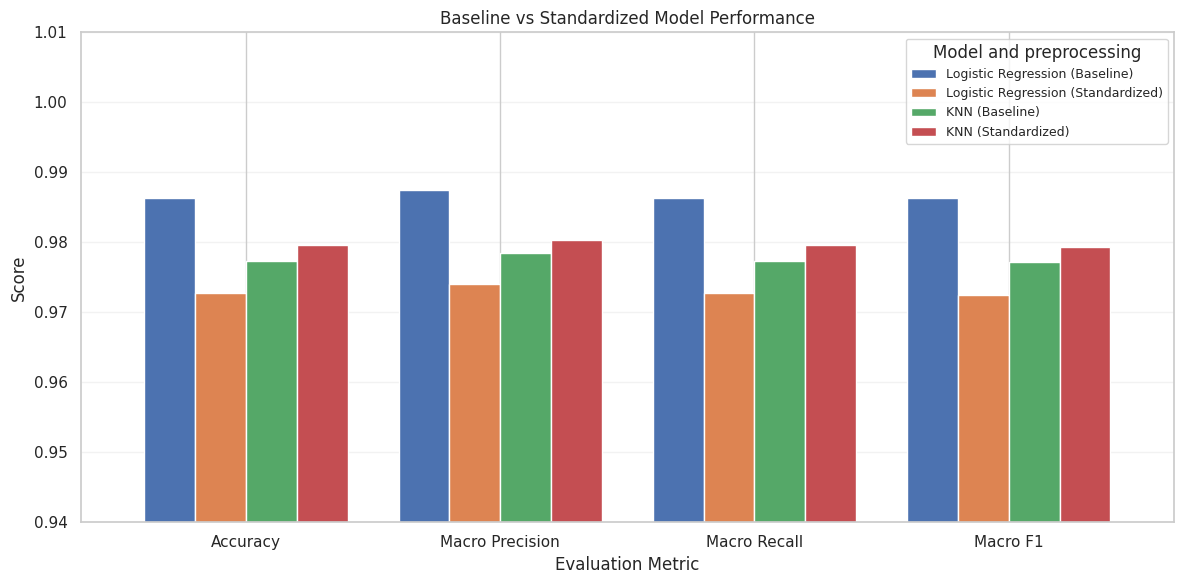

In [ ]:
# Prepare the comparison between standarized and baseline Logistic Regression and KNN  combinations
comparison_df = pd.DataFrame({
    "Logistic Regression (Baseline)": baseline_df["Logistic Regression"],
    "Logistic Regression (Standardized)": standardized_df["Logistic Regression"],
    "KNN (Baseline)": baseline_df["K-Nearest Neighbors"],
    "KNN (Standardized)": standardized_df["K-Nearest Neighbors"]
})

# 4. Plot four grouped bars for each metric
ax = comparison_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Baseline vs Standardized Model Performance")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0.94, 1.01)
ax.set_xticklabels(
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"],
    rotation=0
)

ax.legend(title="Model and preprocessing", fontsize=9)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("fig1_training_model_standardization_comparison.png", dpi=300)
plt.show()

 **Baseline vs standarized model performance figure above**

when comparing the results of the baseline logistic regression and the standarized we notice that the baseline performs better, but this doesnt mean that standarization is not good. Standarization allowed the model to converge faster without taking the whole iterations meaning it was kess expensive.

The standarized KNN performed better than the baseline KNN as expected

***Grid Search***

Testing different combinations of model settings and selecting the combination that performs best according to a chosen evaluation metric.

For each model we definesd a set of parameter values and grid search evaluated all combinations usinf 5 flod cross validation.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOMSTATE)

models_to_tune = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", lr_model)
    ]),
    "Random Forest": rf_model,
    "Decision Tree": dt_model,
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", knn_model)
    ])
}

parameters = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
    },
    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 10, 20]
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10],
        "criterion": ["gini", "entropy"]
    },
    "K-Nearest Neighbors": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    }
}

tuning_results = {}
best_models = {}

for name, model in models_to_tune.items():
  #Apply grid search
  search = GridSearchCV(
      estimator = model,
      param_grid = parameters[name],
      cv = cv,
      scoring = "f1_macro",
      n_jobs = -1
  )
  search.fit(X_train, y_train)
  #store the best model
  best_models[name] = search.best_estimator_
  #Predict using the best model
  y_pred = search.best_estimator_.predict(X_test)
  #calculate the metrics
  scores = metrics(y_test, y_pred)
  #store the metrics
  tuning_results[name] = {
      "best_params": str(search.best_params_),
      "best_cv_score": search.best_score_,
      **scores
  }

  print(f"\n{name}")
  print("Best parameters:", search.best_params_)
  # the best mean cross-validation macro f1 score achieved by the tested combinations
  print("Best CV macro F1:", round(search.best_score_, 4))
  print("Test macro F1:", round(scores["macro_f1"], 4))

tuning_df = pd.DataFrame(tuning_results)
tuning_df.to_csv('3_tuning_results.csv')


Logistic Regression
Best parameters: {'model__C': 10}
Best CV macro F1: 0.977
Test macro F1: 0.9795

Random Forest
Best parameters: {'max_depth': None, 'n_estimators': 200}
Best CV macro F1: 0.9943
Test macro F1: 0.9955

Decision Tree
Best parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 5}
Best CV macro F1: 0.9858
Test macro F1: 0.9794

K-Nearest Neighbors
Best parameters: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
Best CV macro F1: 0.9754
Test macro F1: 0.9817


In [ ]:
print("\nTuning results:")
tuning_df


Tuning results:


,Logistic Regression,Random Forest,Decision Tree,K-Nearest Neighbors
best_params,{'model__C': 10},"{'max_depth': None, 'n_estimators': 200}","{'criterion': 'gini', 'max_depth': None, 'min_...","{'model__n_neighbors': 5, 'model__p': 1, 'mode..."
best_cv_score,0.976997,0.994292,0.985798,0.97544
accuracy,0.979545,0.995455,0.979545,0.981818
macro_precision,0.980876,0.995671,0.980598,0.982348
macro_recall,0.979545,0.995455,0.979545,0.981818
macro_f1,0.979466,0.995452,0.979423,0.98169


cv score is the best mean cross-validation macro f1 score achieved by the tested hyperparameter combinations

In [ ]:
#evaluate training and test performance for all models
metric_names = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1"
]
train_test_metrics = {}

for name,model in best_models.items():
  y_train_pred = model.predict(X_train)
  y_test_pred = model.predict(X_test)

  train_metrics = metrics(y_train, y_train_pred)
  test_metrics = metrics(y_test, y_test_pred)

  #store the difference results
  difference = {}

  for metric in metric_names:
    difference[f"train_{metric}"] = train_metrics[metric]
    difference[f"test_{metric}"] = test_metrics[metric]
    difference[f"gap_{metric}"] = (
        train_metrics[metric] - test_metrics[metric]
    )

  train_test_metrics[name] = difference

train_test_df = pd.DataFrame.from_dict(train_test_metrics, orient ="index")
train_test_df.index.name = "model"

train_test_df.to_csv('4_train_test_difference.csv', index = False)
print("Train vs Test Metrics")
train_test_df


Train vs Test Metrics


,train_accuracy,test_accuracy,gap_accuracy,train_macro_precision,test_macro_precision,gap_macro_precision,train_macro_recall,test_macro_recall,gap_macro_recall,train_macro_f1,test_macro_f1,gap_macro_f1
model,,,,,,,,,,,,
Logistic Regression,0.984659,0.979545,0.005114,0.984717,0.980876,0.003841,0.984659,0.979545,0.005114,0.984625,0.979466,0.005159
Random Forest,1.000000,0.995455,0.004545,1.000000,0.995671,0.004329,1.000000,0.995455,0.004545,1.000000,0.995452,0.004548
Decision Tree,0.998864,0.979545,0.019318,0.998878,0.980598,0.018279,0.998864,0.979545,0.019318,0.998864,0.979423,0.019440
K-Nearest Neighbors,1.000000,0.981818,0.018182,1.000000,0.982348,0.017652,1.000000,0.981818,0.018182,1.000000,0.981690,0.018310


gap in the above table means the difference between the train and test scores. we measures it to check for overfitting and underfitting.

Results: no overfitting or underfitting is observed

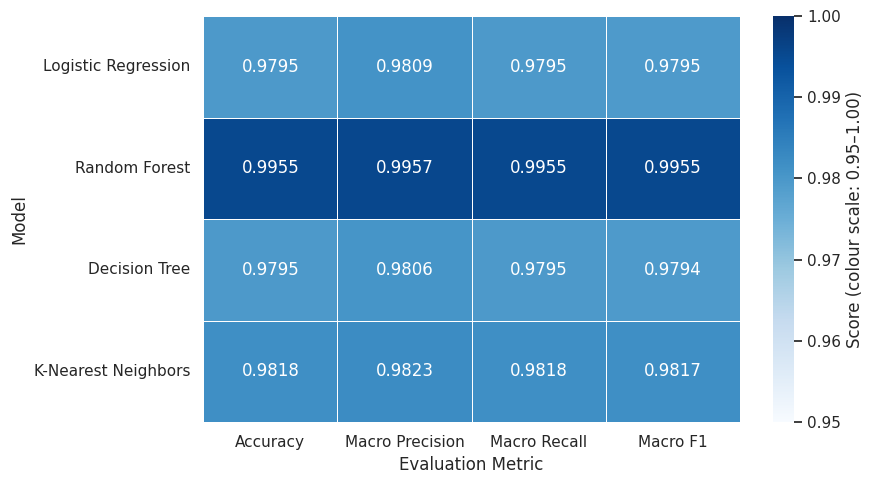

In [ ]:
#create a heatmap to compare the results of the test metrics
train_test_df = train_test_df.reset_index()
test_df = train_test_df.set_index("model")[[
        "test_accuracy",
        "test_macro_precision",
        "test_macro_recall",
        "test_macro_f1"]]

test_df.columns = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]

plt.figure(figsize = (9,5))
sns.heatmap(test_df, annot = True, fmt=".4f", cmap ="Blues", vmin=0.95, vmax =1.00, linewidths=0.5, cbar_kws={"label": "Score (colour scale: 0.95–1.00)"})
plt.xlabel("Evaluation Metric")
plt.ylabel("Model")
plt.tight_layout()
plt.savefig("fig2_results_Test Metrics after tunning heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

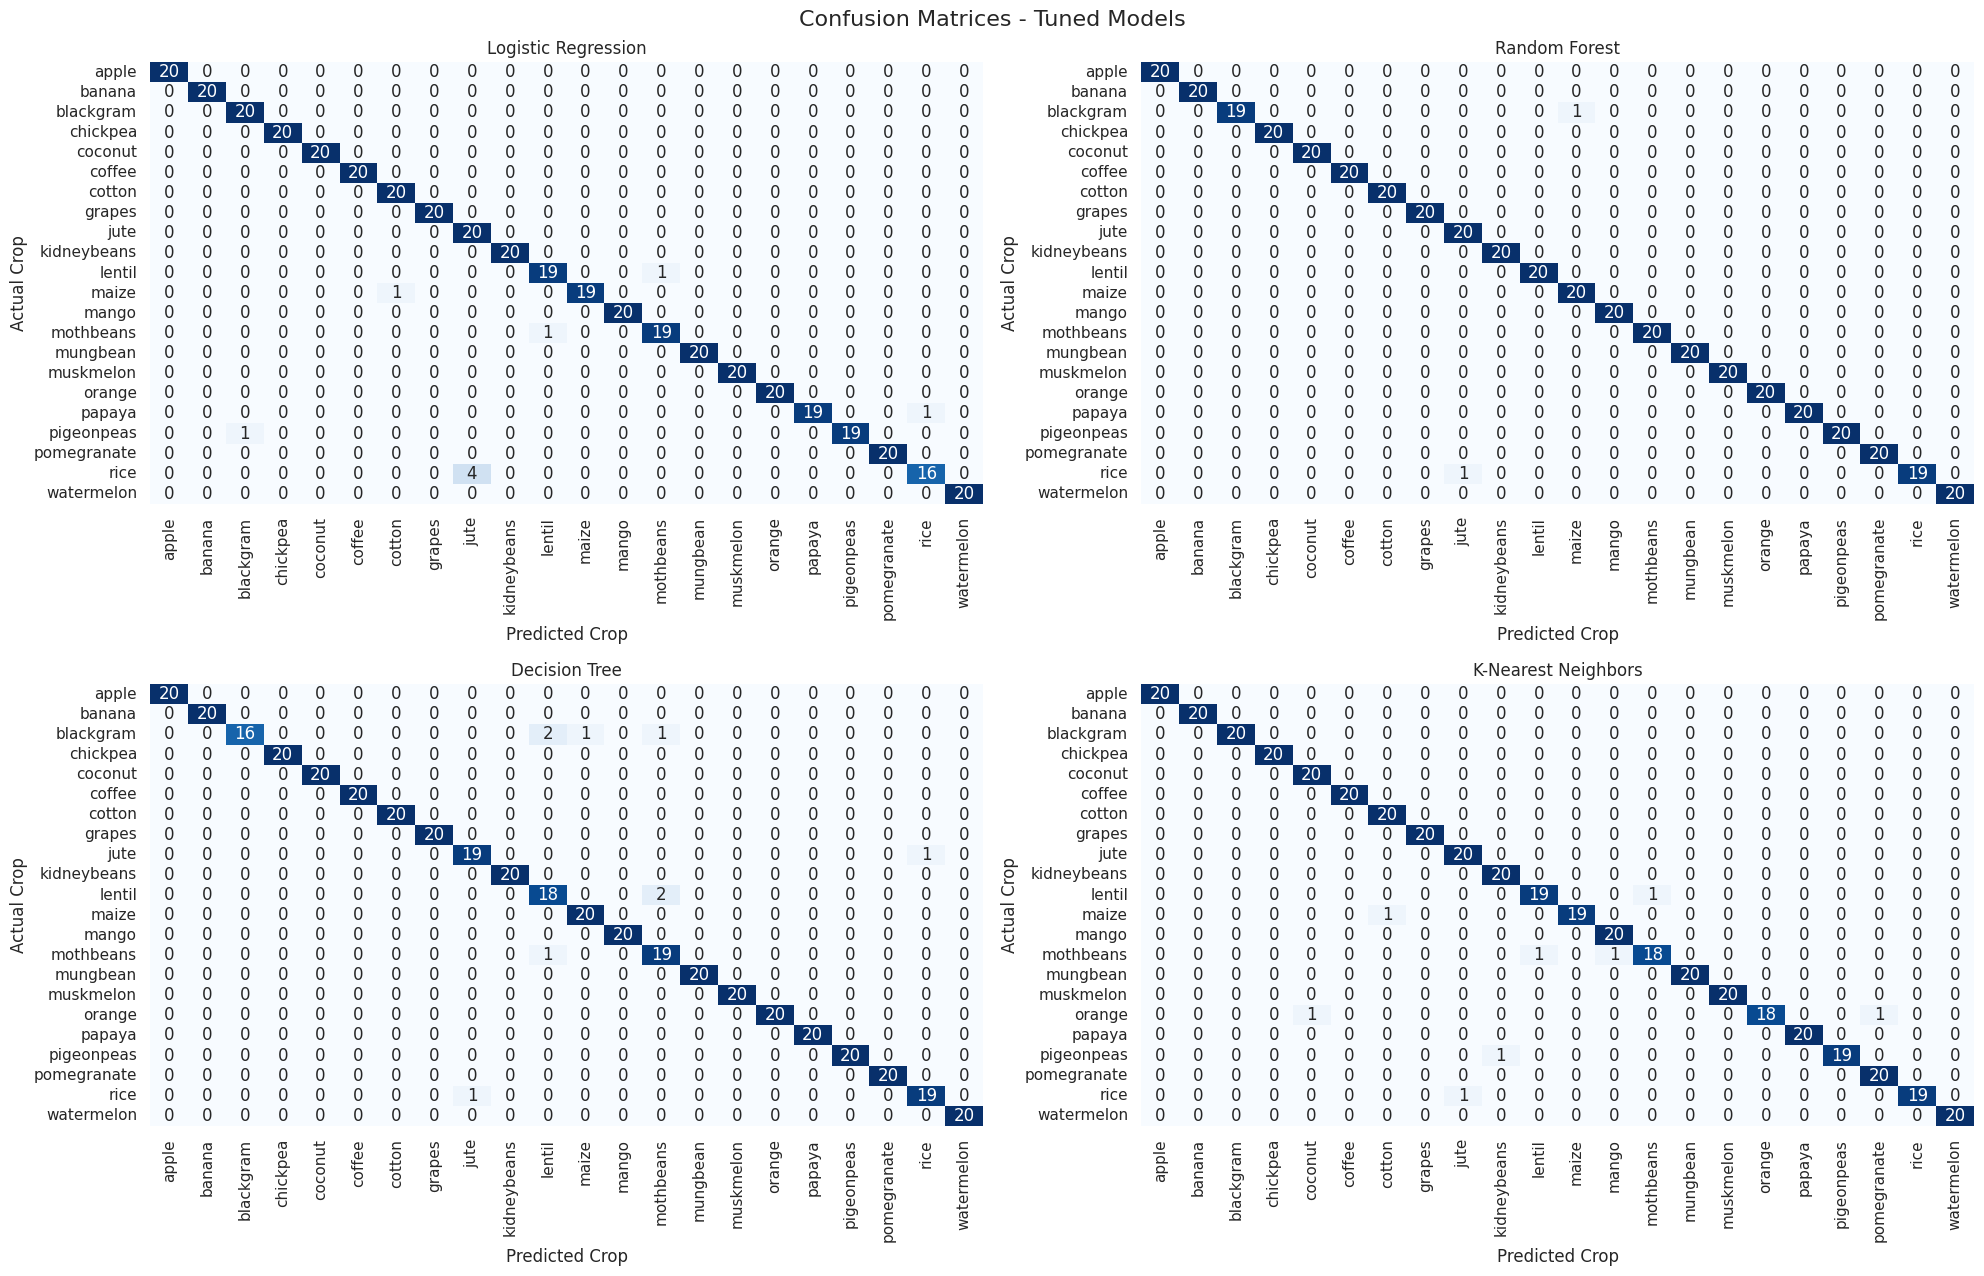

In [ ]:
labels = sorted(df[TARGET].unique())
fig, ax = plt.subplots(2, 2, figsize=(20, 13))
for ax, (name, model) in zip(ax.flat, best_models.items()):
  cm = confusion_matrix(y_test, model.predict(X_test), labels=labels)
  sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=labels, yticklabels=labels)
  ax.set_title(name)
  ax.set_xlabel("Predicted Crop")
  ax.set_ylabel("Actual Crop")
  ax.tick_params(axis="x", rotation=90)
  ax.tick_params(axis="y", rotation=0)
plt.suptitle("Confusion Matrices - Tuned Models", fontsize = 16)
plt.tight_layout()
plt.savefig("fig3_results_confusion_matrices_tuned_models.png", dpi=300)
plt.show()

The confusion matrices above prove that random forest performed best across all model as it is the least model that made mistakes in classifying the crops

## **Choose Best Model**

In [ ]:
def choose_best_model(best_models, X_test, y_test, metrics):

    results = {}

    # Evaluate each tuned model
    for name, model in best_models.items():

        y_pred = model.predict(X_test)
        scores = metrics(y_test, y_pred)
        results[name] = scores

    # Convert results into a DataFrame
    results_df = pd.DataFrame.from_dict(
        results,
        orient="index"
    )

    results_df.index.name = "model"
    results_df = results_df.reset_index()

    # Select the model with the highest macro F1
    best_row = results_df.loc[
        results_df["macro_f1"].idxmax()
    ]

    best_model_name = best_row["model"]
    best_model = best_models[best_model_name]

    # Save  the best model as a joblib file
    joblib.dump(best_model, "best_model.joblib")

    # Save ONLY the best model's results
    best_model_df = pd.DataFrame([best_row])
    best_model_df.to_csv("best_model.csv", index=False)

    print("Best model:", best_model_name)
    print("Test Macro F1:", round(best_row["macro_f1"], 4))
    print("Test Accuracy:", round(best_row["accuracy"], 4))
    print("\nBest model results: ")
    print(best_model_df.round(4).to_string(index = False))

    return best_model_name, best_model, best_model_df

In [ ]:

best_model_name, best_model, best_model_df = choose_best_model(
    best_models,
    X_test,
    y_test,
    metrics
)


Best model: Random Forest
Test Macro F1: 0.9955
Test Accuracy: 0.9955

Best model results: 
        model  accuracy  macro_precision  macro_recall  macro_f1
Random Forest    0.9955           0.9957        0.9955    0.9955
